# Model 2 v2 – 05 Data preparation (more LEG data)
**Why:** Real-world tests (19–20 Oct) showed Model 2 is weak on LEG images from other sources (foot AP → HAND,
lateral knee → HAND/elbow, ankles with metal plates → HAND). Training data: HAND 2,555 vs LEG 643 images,
almost all LEG from one source.
**What is added (LEG only):** (1) the 136 `L*` leg X-rays and (2) up to 200 knee X-rays already on Drive in the
Model 1 folder (never used by Model 2), (3) the new images from a team member (`NEW_DATA/leg_from_teammate`).
**Safety:** exact + near-duplicates of Model 2 images are removed (ORB/RANSAC as in notebook 01), the old Model 2
splits stay unchanged, and 30% of the new images are held back as `newtest` (a real-world LEG test, never trained on).
**Outputs:** outputs/model2_v2/ (manifest_split_v2.csv, cache_224_v2.npz, new_images.csv)

In [21]:
# ===== SETTINGS =====
from pathlib import Path
DRIVE_ROOT    = Path('/content/drive/MyDrive/Research')
M2_DIR        = DRIVE_ROOT / 'outputs' / 'model2'                    # old Model 2 data + models
M1V2_MANIFEST = DRIVE_ROOT / 'outputs' / 'model1_v2' / 'manifest_split_v2.csv'   # has the L* and knee images
TEAM_DIR      = DRIVE_ROOT / 'NEW_DATA' / 'leg_from_teammate'        # her zip, extracted, folder names kept
OUT_DIR       = DRIVE_ROOT / 'outputs' / 'model2_v2'

SEED, IMG_SIZE = 42, 224
N_KNEE        = 200     # knee X-rays to add (capped so the knee format does not dominate LEG)
NEWTEST_FRAC  = 0.30    # share of new images held back as a real-world LEG test
VAL_FRAC      = 0.15    # share of new images added to validation
LINK_T        = 15      # ORB/RANSAC inliers = same X-ray (validated in Model 2 notebook 01)
FORCE_NEWTEST = ['L37.png', 'L120.png']   # images already tested in the app -> always in the held-back test

# Filled in AFTER looking at the Step 3 grid (short region names), then re-run from Step 3:
LABEL_FIXES = {'L107.png': 'Hip to knee', 'L128.png': 'Foot and ankle', 'L94.png': 'Foot and ankle', 'L96.png': 'Foot and ankle'}       # e.g. {'L105.png': 'Knee to ankle', 'LL108.PNG': 'Foot and ankle'}
EXCLUDE     = []        # files that are not leg X-rays, e.g. ['L131.png']

In [22]:
!pip install -q timm
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, pandas as pd, torch, torch.nn as nn, timm, hashlib, io, cv2, matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tqdm.auto import tqdm
device = 'cuda' if torch.cuda.is_available() else 'cpu'
OUT_DIR.mkdir(parents=True, exist_ok=True)

m2 = pd.read_csv(M2_DIR / 'manifest_split.csv')
c2 = np.load(M2_DIR / 'cache_224.npz', allow_pickle=True); X2, P2 = c2['images'], c2['paths']
assert (P2[m2.cache_idx] == m2.path).all(), 'Model 2 manifest and cache do not match!'
md5_m2 = set(pd.read_csv(M2_DIR / 'inventory_full.csv').md5.dropna())
CLASSES = sorted(m2.label.unique())
FULL = {c.split(' - ')[0]: c for c in CLASSES}            # short name -> full class name
LEG = ['Foot and ankle', 'Hip to knee', 'Knee to ankle']
print('Model 2 data:', m2.shape, '| cache', X2.shape, '| device', device)
print('Classes:', list(FULL))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model 2 data: (3682, 14) | cache (3712, 224, 224) | device cuda
Classes: ['Elbow to wrist', 'Foot and ankle', 'Hip to knee', 'Knee to ankle', 'OTHER', 'Shoulder to elbow', 'Wrist and hand']


## Step 1 – Collect the candidate LEG images
`L*` and knee images come from the Model 1 v2 manifest (rows already checked there against Model 2 copies);
team-member images are read from her folders (folder name → region).

In [23]:
IMG_SIZE = IMG_SIZE

def prep_pil(im):                                   # identical to Model 2 data preparation (notebook 01)
    im = ImageOps.exif_transpose(im)
    if im.mode in ('I;16', 'I;16B', 'I;16L', 'I', 'F'):
        a = np.asarray(im, dtype=np.float32); a = (a - a.min()) / max(a.max() - a.min(), 1) * 255
        im = Image.fromarray(a.astype(np.uint8))
    if im.mode == 'P': im = im.convert('RGBA')
    if im.mode in ('RGBA', 'LA'):
        bg = Image.new('RGBA', im.size, (0, 0, 0, 255)); im = Image.alpha_composite(bg, im.convert('RGBA'))
    im = im.convert('L'); w, h = im.size; s = max(w, h)
    canvas = Image.new('L', (s, s), 0); canvas.paste(im, ((s - w) // 2, (s - h) // 2))
    return np.asarray(canvas.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.uint8)

m1 = pd.read_csv(M1V2_MANIFEST)
m1['filename'] = m1.path.str.rsplit('/', n=1).str[1]
L = m1[m1.source == 'v1_other_xray'].assign(source='L_leg', label=None)
knee_all = m1[m1.source == 'v1_knee_kaggle']
knee = knee_all.groupby(knee_all.filename.str.extract(r'^([A-Za-z]+)')[0], group_keys=False) \
               .apply(lambda g: g.sample(min(len(g), round(N_KNEE * len(g) / len(knee_all))), random_state=SEED))
knee = knee.assign(source='knee', label='Hip to knee')    # knee joint: patella/distal femur (team folder convention)

def team_label(folder):
    f = folder.lower()
    return 'Foot and ankle' if f.startswith('foot') else 'Hip to knee' if f.startswith('hip') else \
           'Knee to ankle' if f.startswith('knee') else None
team = pd.DataFrame([{'path': str(p), 'filename': p.name, 'source': 'teammate', 'label': team_label(p.parent.name)}
                     for p in sorted(TEAM_DIR.rglob('*')) if p.is_file() and p.suffix.lower() in {'.png', '.jpg', '.jpeg'}])
print('Team folders:', team.groupby(team.path.str.rsplit('/', n=2).str[1]).size().to_dict() if len(team) else 'none found!')

new = pd.concat([L[['path', 'filename', 'source', 'label']], knee[['path', 'filename', 'source', 'label']], team],
                ignore_index=True)
rows, imgs = [], []
for r in tqdm(new.itertuples(), total=len(new)):
    try:
        data = Path(r.path).read_bytes()
        with Image.open(io.BytesIO(data)) as im: imgs.append(prep_pil(im))
        rows.append(dict(r._asdict(), md5=hashlib.md5(data).hexdigest()))
    except Exception as e:
        print('unreadable:', r.filename, str(e)[:60])
new = pd.DataFrame(rows).drop(columns='Index'); Xn = np.stack(imgs)
new['removed'] = ''
print('\nCandidates:', new.groupby('source').size().to_dict(), '| array', Xn.shape)

Team folders: {'Foot and toes-Talus, calcaneus, navicular, cuboid, cuneiform, metatarsals, phalanges': 29, 'Hip to knee - Femur, patella': 37, 'Knee to ankle-Tibia, fibula': 38}


  0%|          | 0/440 [00:00<?, ?it/s]


Candidates: {'L_leg': 136, 'knee': 200, 'teammate': 104} | array (440, 224, 224)


## Step 2 – Remove duplicates
(a) exact copies (MD5) of Model 2 files and inside the new set; (b) near-copies of Model 2 images:
MobileNetV3 shortlist (5 nearest, incl. mirrored) + ORB/RANSAC inliers ≥ 15, exactly as in Model 2 notebook 01.

In [24]:
new.loc[new.md5.isin(md5_m2), 'removed'] = 'exact_copy_of_model2'
new.loc[(new.removed == '') & new.md5.duplicated(), 'removed'] = 'exact_copy_inside_new'
print(new.groupby(['source', 'removed']).size().to_string())

source    removed              
L_leg                              136
knee                               200
teammate                            54
          exact_copy_inside_new     24
          exact_copy_of_model2      26


In [25]:
from torchvision.models import mobilenet_v3_large, MobileNet_V3_Large_Weights
net = mobilenet_v3_large(weights=MobileNet_V3_Large_Weights.IMAGENET1K_V2); net.classifier = nn.Identity(); net.eval().to(device)
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1).to(device); STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1).to(device)
@torch.no_grad()
def embed(arr):
    out = []
    for i in range(0, len(arr), 128):
        x = torch.from_numpy(np.ascontiguousarray(arr[i:i+128])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
        out.append(torch.nn.functional.normalize(net((x - MEAN) / STD), dim=1).cpu())
    return torch.cat(out).numpy()

orb, clahe, bf = cv2.ORB_create(nfeatures=1000), cv2.createCLAHE(2.0, (8, 8)), cv2.BFMatcher(cv2.NORM_HAMMING)
def orb_feats(img): return orb.detectAndCompute(cv2.resize(clahe.apply(img), (448, 448)), None)
def inliers(fa, fb):
    (ka, da), (kb, db) = fa, fb
    if da is None or db is None or len(ka) < 10 or len(kb) < 10: return 0
    good = [p[0] for p in bf.knnMatch(da, db, k=2) if len(p) == 2 and p[0].distance < 0.75 * p[1].distance]
    if len(good) < 8: return 0
    pa = np.float32([ka[m.queryIdx].pt for m in good]); pb = np.float32([kb[m.trainIdx].pt for m in good])
    _, mask = cv2.estimateAffinePartial2D(pa, pb, method=cv2.RANSAC, ransacReprojThreshold=5.0)
    return 0 if mask is None else int(mask.sum())

idx2 = m2.cache_idx.values                                 # Model 2 images (all splits)
E2, E2f, En = embed(X2[idx2]), embed(np.ascontiguousarray(X2[idx2][:, :, ::-1])), embed(Xn)
S = np.maximum(En @ E2.T, En @ E2f.T); nn5 = np.argsort(-S, axis=1)[:, :5]
fn  = [orb_feats(x) for x in tqdm(Xn, desc='ORB new')]
need = np.unique(nn5); f2 = {k: orb_feats(X2[idx2[k]]) for k in tqdm(need, desc='ORB Model 2')}
f2f = {k: orb_feats(np.ascontiguousarray(X2[idx2[k]][:, ::-1])) for k in need}
best = [max((max(inliers(fn[i], f2[k]), inliers(fn[i], f2f[k])), k) for k in nn5[i]) for i in tqdm(range(len(Xn)), desc='verify')]
new['m2_inliers'] = [b[0] for b in best]; new['m2_match'] = [m2.filename.iloc[b[1]] for b in best]
new['m2_match_split'] = [m2.split.iloc[b[1]] for b in best]
hit = (new.removed == '') & (new.m2_inliers >= LINK_T)
new.loc[hit, 'removed'] = 'near_copy_of_model2'
print('Near-copies of Model 2 images (by source, matched Model 2 split):')
print(new[hit].groupby(['source', 'm2_match_split']).size().to_string() if hit.any() else 'none')

ORB new:   0%|          | 0/440 [00:00<?, ?it/s]

ORB Model 2:   0%|          | 0/502 [00:00<?, ?it/s]

verify:   0%|          | 0/440 [00:00<?, ?it/s]

Near-copies of Model 2 images (by source, matched Model 2 split):
source    m2_match_split
teammate  test              1
          train             8
          val               1


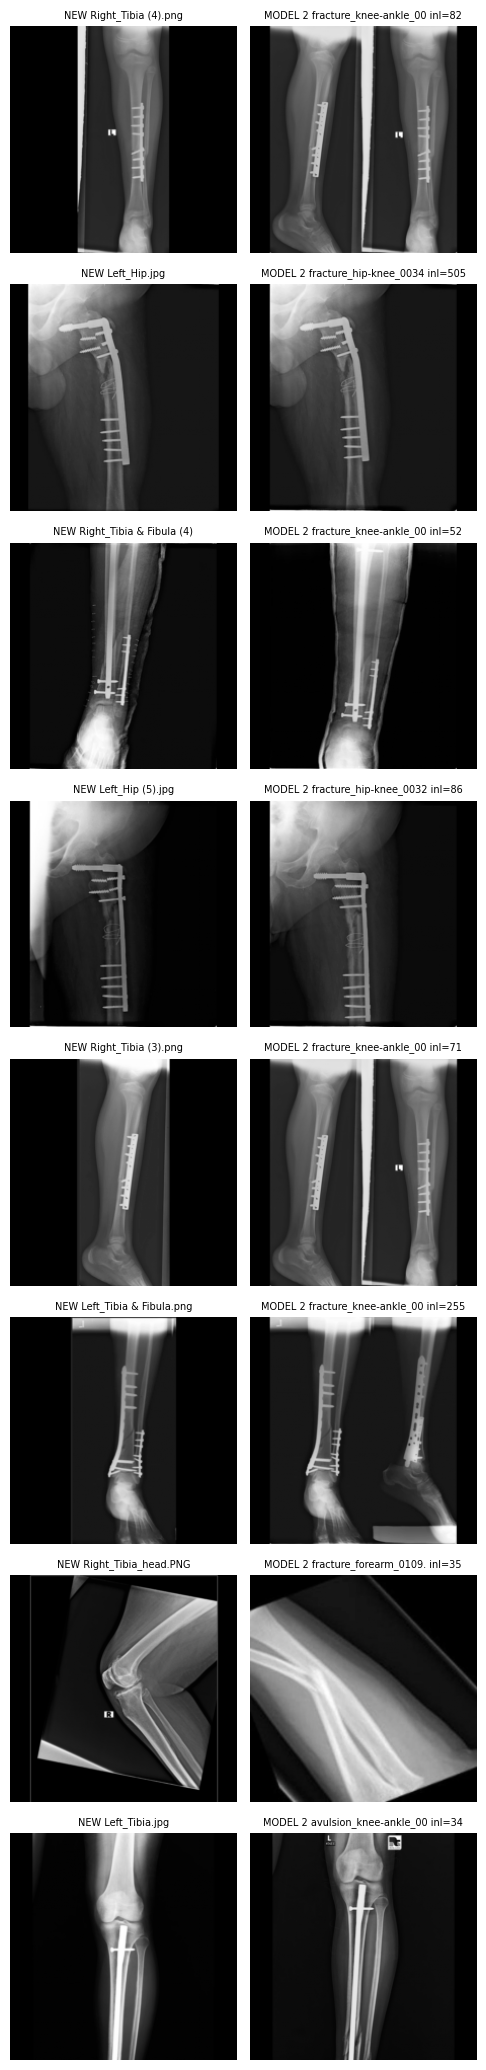

In [26]:
def show_matches(n=8):                                     # visual check of the removed near-copies
    sub = new[new.removed == 'near_copy_of_model2']
    if len(sub) == 0: print('No near-copies.'); return
    sub = sub.sample(min(n, len(sub)), random_state=SEED)
    fig, axes = plt.subplots(len(sub), 2, figsize=(5, 2.6 * len(sub))); axes = np.atleast_2d(axes)
    for row, (i, r) in zip(axes, sub.iterrows()):
        j = m2.index[m2.filename == r.m2_match][0]
        row[0].imshow(Xn[i], cmap='gray'); row[0].set_title(f'NEW {r.filename[:24]}', fontsize=7)
        row[1].imshow(X2[m2.cache_idx[j]], cmap='gray'); row[1].set_title(f'MODEL 2 {r.m2_match[:22]} inl={r.m2_inliers}', fontsize=7)
        for a in row: a.axis('off')
    plt.tight_layout(); plt.show()
show_matches()

In [27]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
keep = np.where(new.removed == '')[0]                           # near-copies INSIDE the new set -> groups
Sn = En[keep] @ En[keep].T; np.fill_diagonal(Sn, -1)
pairs = {(min(a, b), max(a, b)) for a in range(len(keep)) for b in np.argsort(-Sn[a])[:5]}
links = [(a, b) for a, b in tqdm(pairs, desc='groups') if inliers(fn[keep[a]], fn[keep[b]]) >= LINK_T]
A = coo_matrix((np.ones(len(links)), ([a for a, _ in links], [b for _, b in links])), shape=(len(keep),) * 2)
_, gid = connected_components(A, directed=False)
new['group'] = -1; new.loc[keep, 'group'] = gid
print('Kept new images:', len(keep), '| groups:', len(set(gid)), '| images with a copy inside the new set:',
      int((pd.Series(gid).map(pd.Series(gid).value_counts()) > 1).sum()))
print(new[new.removed == ''].groupby('source').size().to_string())

groups:   0%|          | 0/1427 [00:00<?, ?it/s]

Kept new images: 380 | groups: 308 | images with a copy inside the new set: 105
source
L_leg       136
knee        200
teammate     44


## Step 3 – Region labels for the `L*` images (model suggestion + your check)
The current Model 2 ensemble suggests one of the 3 LEG regions for each `L*` image (it may only choose LEG regions,
since all `L*` images are leg X-rays). **Look at every image:** wrong region → add to `LABEL_FIXES`; not a leg
X-ray → add to `EXCLUDE` (settings cell), then re-run from this step. Team images keep their folder label.

In [28]:
from torchvision.models import mobilenet_v3_large
def load_m2(path):
    ck = torch.load(path, map_location=device, weights_only=False)
    if ck.get('timm_name', 'torchvision') == 'torchvision':
        m = mobilenet_v3_large(); m.classifier[3] = nn.Linear(m.classifier[3].in_features, len(ck['classes']))
    else:
        m = timm.create_model(ck['timm_name'], pretrained=False, num_classes=len(ck['classes']))
    m.load_state_dict(ck['state_dict']); return m.eval().to(device), ck['mean'], ck['std'], ck['classes']

@torch.no_grad()
def predict_arr(model, mean, std, arr):
    mean = torch.tensor(mean).view(1, 3, 1, 1).to(device); std = torch.tensor(std).view(1, 3, 1, 1).to(device)
    out = []
    for k in range(0, len(arr), 64):
        t = torch.from_numpy(np.ascontiguousarray(arr[k:k+64])).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(device)
        out.append(torch.softmax(model((t - mean) / std), 1).cpu().numpy())
    return np.concatenate(out)

mL = (new.source == 'L_leg') & (new.removed == '')
P = np.mean([predict_arr(*load_m2(M2_DIR / f)[:3], Xn[mL.values])
             for f in ['mobilenetv3_model2_best.pt', 'deit_small_model2_best.pt']], axis=0)
legcols = [CLASSES.index(FULL[s]) for s in LEG]
new.loc[mL, 'suggested'] = [LEG[k] for k in P[:, legcols].argmax(1)]
new.loc[mL, 'p_leg_model2'] = P[:, legcols].sum(1).round(2)       # how LEG-like the OLD model finds it
new.loc[mL, 'label'] = new.loc[mL, 'suggested']
for f, lab in LABEL_FIXES.items():
    assert lab in LEG, f'{lab} is not one of {LEG}'
    new.loc[new.filename == f, 'label'] = lab
new.loc[new.filename.isin(EXCLUDE), 'removed'] = 'excluded_by_you'
print('L* labels:', new[mL].label.value_counts().to_dict(), '| fixes', len(LABEL_FIXES), '| excluded', len(EXCLUDE))
print(f'Old model calls {(new[mL].p_leg_model2 < 0.5).mean():.0%} of these leg X-rays NOT LEG (why we need them)')

L* labels: {'Hip to knee': 67, 'Foot and ankle': 48, 'Knee to ankle': 21} | fixes 4 | excluded 0
Old model calls 10% of these leg X-rays NOT LEG (why we need them)


In [29]:
show = new[(new.source == 'L_leg')].reset_index()
for start in range(0, len(show), 30):
    part = show.iloc[start:start + 30]
    fig, axes = plt.subplots(5, 6, figsize=(15, 13.5))
    for ax in axes.flat: ax.axis('off')
    for ax, (_, r) in zip(axes.flat, part.iterrows()):
        ax.imshow(Xn[r['index']], cmap='gray')
        tag = 'REMOVED: ' + r['removed'] if r['removed'] else r['label']
        ax.set_title(f"{r.filename}\n{tag}", fontsize=8, color='red' if r['removed'] else 'black')
    plt.tight_layout(); plt.show()

Output hidden; open in https://colab.research.google.com to view.

## Step 4 – Split the new images and build the v2 dataset
Old Model 2 rows keep their split (so old and new models are compared on the same 519 test images).
New images: 30% `newtest` (held back, group-aware, the app-tested images forced in), 15% `val`, rest `train`.

In [30]:
add = new[new.removed == ''].copy()
add['label'] = add.label.map(FULL); assert add.label.notna().all()
rng = np.random.default_rng(SEED); add['split'] = 'train'
forced = set(add.loc[add.filename.isin(FORCE_NEWTEST), 'group'])
for (src, lab), g in add.groupby(['source', 'label']):         # group-aware split per source and region
    groups = [x for x in rng.permutation(g.group.unique()) if x not in forced]
    sizes = g.group.value_counts(); n = len(g); a = b = 0
    for x in groups:
        if a < NEWTEST_FRAC * n: add.loc[add.group == x, 'split'] = 'newtest'; a += sizes[x]
        elif b < VAL_FRAC * n:   add.loc[add.group == x, 'split'] = 'val';     b += sizes[x]
add.loc[add.group.isin(forced), 'split'] = 'newtest'
add['super_label'], add['fine_label'] = 'LEG', add.label
add['dup_group'] = 'new_' + add.group.astype(str)
add['cache_idx'] = len(X2) + add.index.values                  # appended after the old cache rows

old = m2.copy(); old['dup_group'] = old.dup_group.astype(str)
cols = ['path', 'filename', 'super_label', 'fine_label', 'label', 'source', 'split', 'dup_group', 'cache_idx']
data = pd.concat([old[cols], add[cols]], ignore_index=True)
X3 = np.concatenate([X2, Xn]); P3 = np.concatenate([P2.astype(str), new.path.values.astype(str)])
assert (P3[data.cache_idx.values] == data.path.values).all(), 'Manifest and cache do not match!'
np.savez_compressed(OUT_DIR / 'cache_224_v2.npz', images=X3, paths=P3)
data.to_csv(OUT_DIR / 'manifest_split_v2.csv', index=False)
new.to_csv(OUT_DIR / 'new_images.csv', index=False)

SUP = lambda l: 'OTHER' if l == 'OTHER' else 'LEG' if l.split(' - ')[0] in LEG else 'HAND'
data['super'] = data.label.map(SUP)
print(pd.crosstab(data.label.str.split(' - ').str[0], data.split, margins=True).to_string())
print('\nHAND/LEG/OTHER in TRAIN: before', m2[m2.split == 'train'].label.map(SUP).value_counts().to_dict(),
      '| after', data[data.split == 'train'].super.value_counts().to_dict())
print('Groups across splits (new images):', (add.groupby('group').split.nunique() > 1).sum())
print('Saved:', OUT_DIR / 'manifest_split_v2.csv', '| cache', X3.shape)

split              newtest  test  train  val   All
label                                             
Elbow to wrist           0    83    442   82   607
Foot and ankle          33    12     99   31   175
Hip to knee             85    35    322   73   515
Knee to ankle           12    40    224   57   333
OTHER                    0    70    345   69   484
Shoulder to elbow        0    75    360   68   503
Wrist and hand           0   204   1031  210  1445
All                    130   519   2823  590  4062

HAND/LEG/OTHER in TRAIN: before {'HAND': 1833, 'LEG': 460, 'OTHER': 345} | after {'HAND': 1833, 'LEG': 645, 'OTHER': 345}
Groups across splits (new images): 0
Saved: /content/drive/MyDrive/Research/outputs/model2_v2/manifest_split_v2.csv | cache (4152, 224, 224)


## Summary – Model 2 v2 data
Candidates: 136 L* leg X-rays + 200 knee X-rays (Model 1 folder, never used by Model 2) + 104 team-member images.
Removed: 26 exact copies of Model 2 images, 24 exact copies inside the new set, 10 near-copies of Model 2 images
(ORB/RANSAC ≥15 inliers; 2 of them matched Model 2 val/test → leakage prevented). Kept: 380 new LEG images.
L* region labels: model suggestion (LEG regions only) checked by eye, 4 corrected. Knees labelled Hip to knee.
The old Model 2 called 10% of the L* leg X-rays NOT LEG.
Split of new images: 130 held back as newtest (real-world LEG test, L37/L120 forced in), val + train; groups across splits: 0.
Old Model 2 splits unchanged (same 519-image test). LEG in train: 460 → 645 (HAND 1,833, OTHER 345).